# 1. Problem definition and data understanding

**Rubric section:** Problem Definition and Data Understanding (10 pts).

**Problem.** Given a short text, predict whether a human or an AI wrote it.
This is **binary classification**. The target is `Label` (0 = Human, 1 = AI).

**Questions we want to answer**
- Can simple, explainable statistics of a text separate human writing from AI writing?
- Which text properties carry that signal?
- Does the result hold for writing styles (templates) the model has never seen?

**Notebook series** (run in order; each one reads files the earlier steps wrote):
1. `01_problem_and_data_understanding.ipynb`
2. `02_preprocessing_and_features.ipynb`
3. `03_logistic_regression.ipynb`
4. `04_random_forest.ipynb`
5. `05_model_comparison.ipynb`

The notebooks call the tested scripts in `src/`, so a notebook and its script always
produce the same numbers. Setup and data download steps are in the repository `README.md`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

# Works whether Jupyter starts in the repo root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

FIGURES = ROOT / "reports" / "figures"
METRICS = ROOT / "reports" / "metrics"
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)


def show(name: str, width: int = 800) -> None:
    """Display a saved figure from reports/figures."""
    display(Image(filename=str(FIGURES / name), width=width))

## Dataset and source

Kaggle: [`datascikhan/ai-vs-human-text-classification-benchmark-50k`](https://www.kaggle.com/datasets/datascikhan/ai-vs-human-text-classification-benchmark-50k), version 1.
`python src/prepare_data.py` downloads it to `data/raw/`. The raw file is never edited.

In [2]:
from data_loader import RAW_CSV_PATH

raw = pd.read_csv(RAW_CSV_PATH)
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
raw.head(3)

Rows: 50,000   Columns: 30


/Users/lucascoelho/Desktop/fall-2026/csce-478/project/human-vs-ai-ml-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Text_ID,Raw_Text,Label,Source_Model,Model_Size,Model_Temperature,Generation_Prompt_Type,RAG_Context_Provided,Detection_Score_Benchmark_Model_A,Word_Count,...,Stopword_Density,Flesch_Kincaid_Grade_Level,Smog_Index,Average_Syllables_Per_Word,Contains_Code_Snippet,Capital_Letter_Count,Formal_Tone_Score,Emotion_Tone_Intensity,Coherence_Score,Burstiness_Score
0,TXT_09927,History has always been a subject of intense debate. Some argue that history...,0,Human_Origin,Human,NaN,Human_Writing,Human,21.510198,219,...,0.438356,11.785556,12.522536,2.027397,0,28,100.000000,16.518485,81.544039,48.832741
1,TXT_35284,"When it comes Similarly, Philosophy, there are several schools of thought. T...",0,Human_Origin,Human,NaN,Human_Writing,Human,78.303093,293,...,0.457338,11.612546,11.958738,2.000000,0,37,100.000000,23.965492,93.325738,65.352863
2,TXT_27383,Let me tell you about Programming. It's one of those topics that everyone ha...,0,Human_Origin,Human,NaN,Human_Writing,Human,83.110976,161,...,0.496894,11.031269,12.423615,1.850932,0,20,91.519314,31.751173,57.563496,58.196010


## Column types and missing values

In [3]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (100 * raw.isna().mean()).round(2),
    "unique_values": raw.nunique(),
})
overview

,dtype,missing,missing_%,unique_values
Text_ID,str,0,0.0,50000
Raw_Text,str,0,0.0,50000
Label,int64,0,0.0,2
Source_Model,str,0,0.0,6
Model_Size,str,0,0.0,4
Model_Temperature,float64,25000,50.0,91
Generation_Prompt_Type,str,0,0.0,11
RAG_Context_Provided,str,0,0.0,3
Detection_Score_Benchmark_Model_A,float64,0,0.0,48107
Word_Count,int64,0,0.0,886


## Class balance

In [4]:
balance = raw["Label"].map({0: "Human", 1: "AI"}).value_counts().to_frame("rows")
balance["share"] = (balance["rows"] / len(raw)).round(3)
balance

,rows,share
Label,,
Human,25000,0.5
AI,25000,0.5


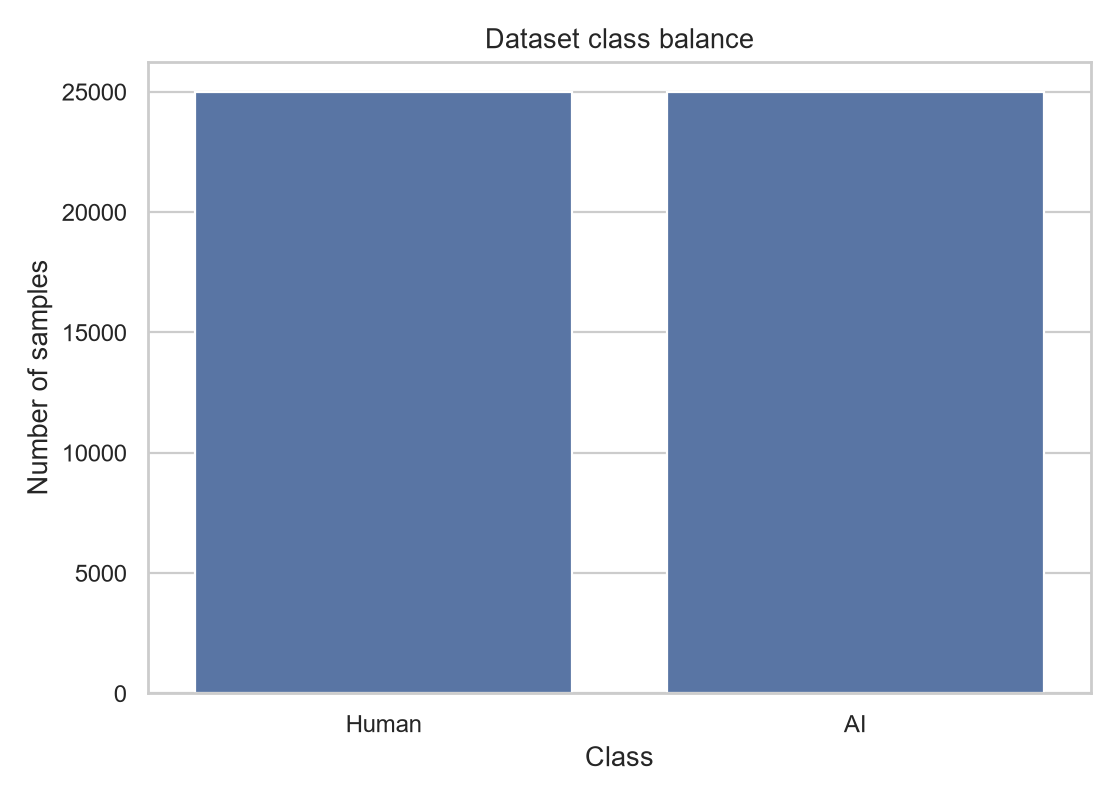

In [5]:
show("class_balance.png", 500)

The classes are exactly balanced (25,000 each), so accuracy is a meaningful metric
and no class weighting or resampling is needed.

## Duplicates

In [6]:
print("Duplicate Text_ID values:", raw["Text_ID"].duplicated().sum())
print("Exact duplicate texts:   ", raw["Raw_Text"].duplicated().sum())

Duplicate Text_ID values: 0
Exact duplicate texts:    0


There are no exact duplicates. Near-duplicates (texts that are almost the same)
are handled in notebook 02, because they could leak between training and test sets.

## Data-quality concerns: columns that give the answer away

Some metadata columns describe how the dataset was built, not the text itself.
They separate the classes perfectly, so a model using them would be cheating.

In [7]:
pd.crosstab(raw["Source_Model"], raw["Label"].map({0: "Human", 1: "AI"}))

Label,AI,Human
Source_Model,,
ChatGPT-4o,4963,0
Claude-3.5-Sonnet,4923,0
Gemini-1.5-Pro,5028,0
Human_Origin,0,25000
Llama-3-70B,5014,0
Mistral-Large,5072,0


In [8]:
missing_by_class = raw.groupby(raw["Label"].map({0: "Human", 1: "AI"}))[
    ["Model_Temperature", "Model_Size"]
].apply(lambda g: g.isna().mean().round(3))
missing_by_class

,Model_Temperature,Model_Size
Label,,
AI,0.0,0.0
Human,1.0,0.0


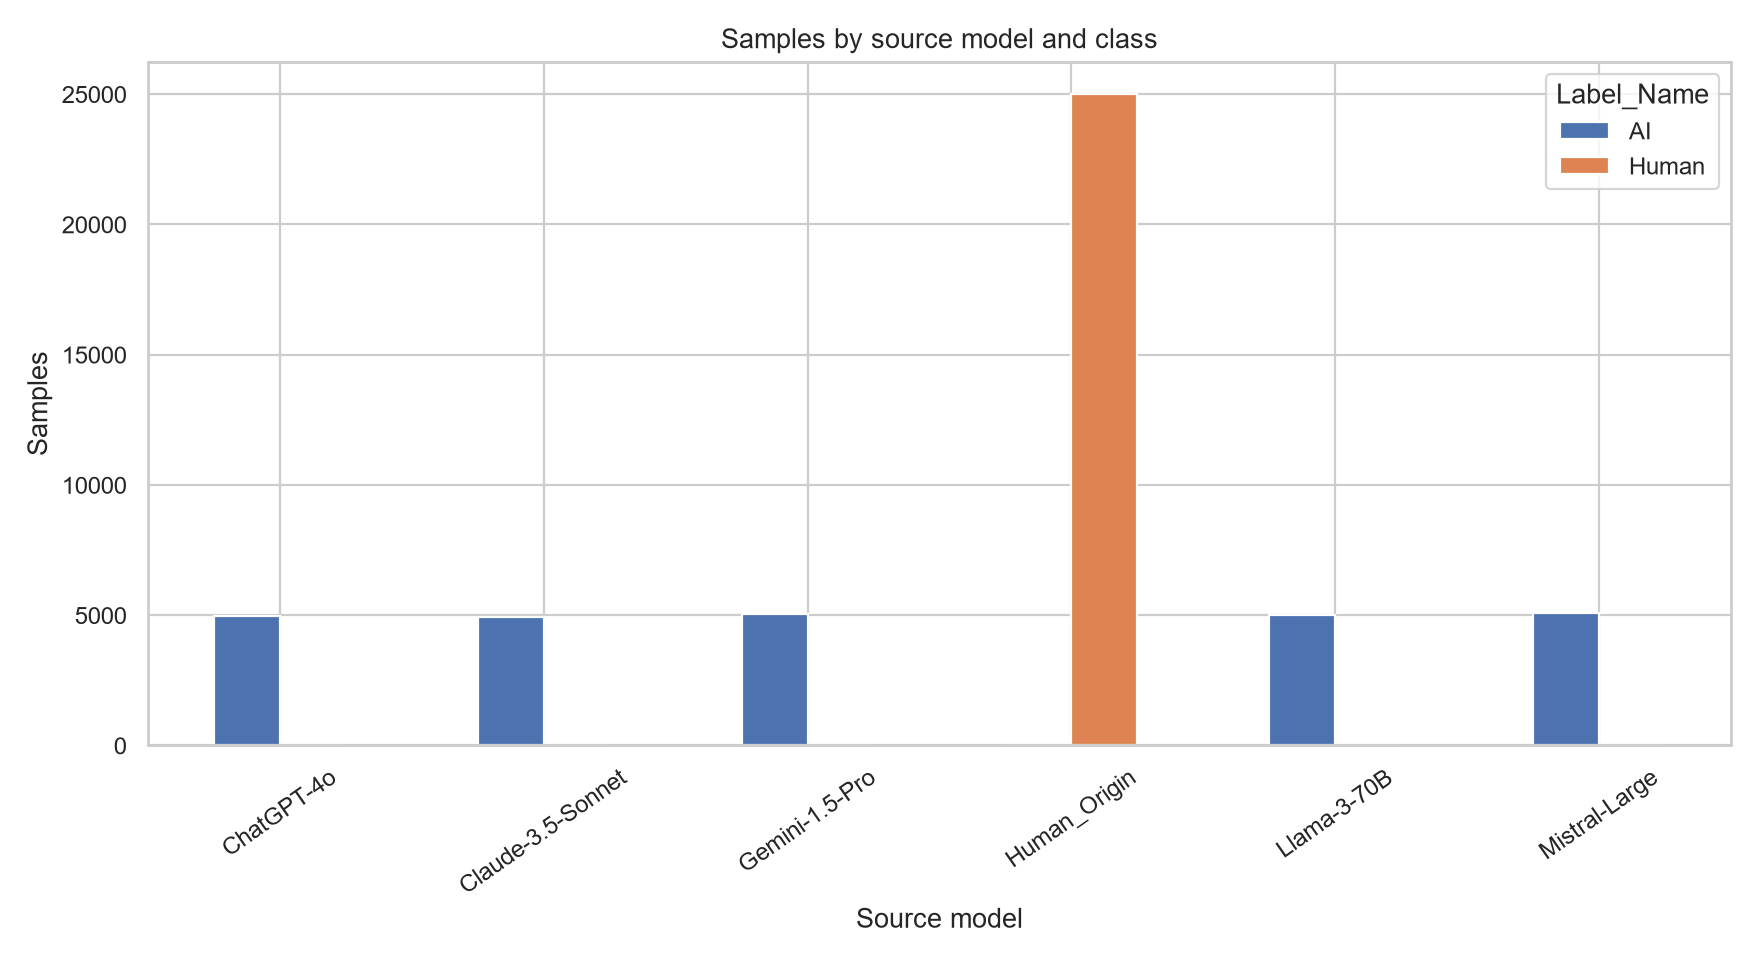

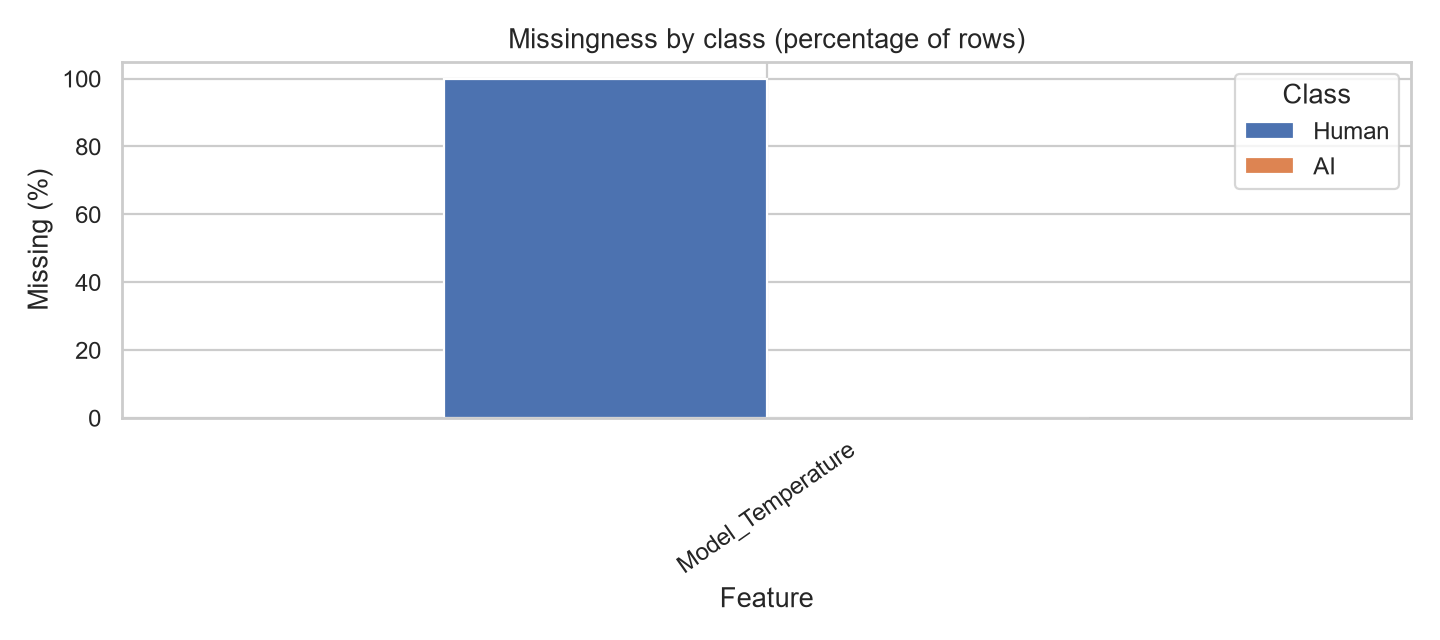

In [9]:
show("source_model_by_class.png", 650)
show("missingness_by_class.png", 650)

- `Source_Model` is `Human_Origin` for every human row, so it **is** the label.
- `Model_Temperature` and `Model_Size` are missing only for human rows, so missingness also reveals the label.
- `Contains_Code_Snippet` is constant, so it carries no information.

**Decision (owner-approved):** dataset-construction metadata is excluded from model inputs.

## The benchmark's own detector score

`Detection_Score_Benchmark_Model_A` is a score from an existing detector. We keep it
only as an external **reference** to compare against, never as an input.

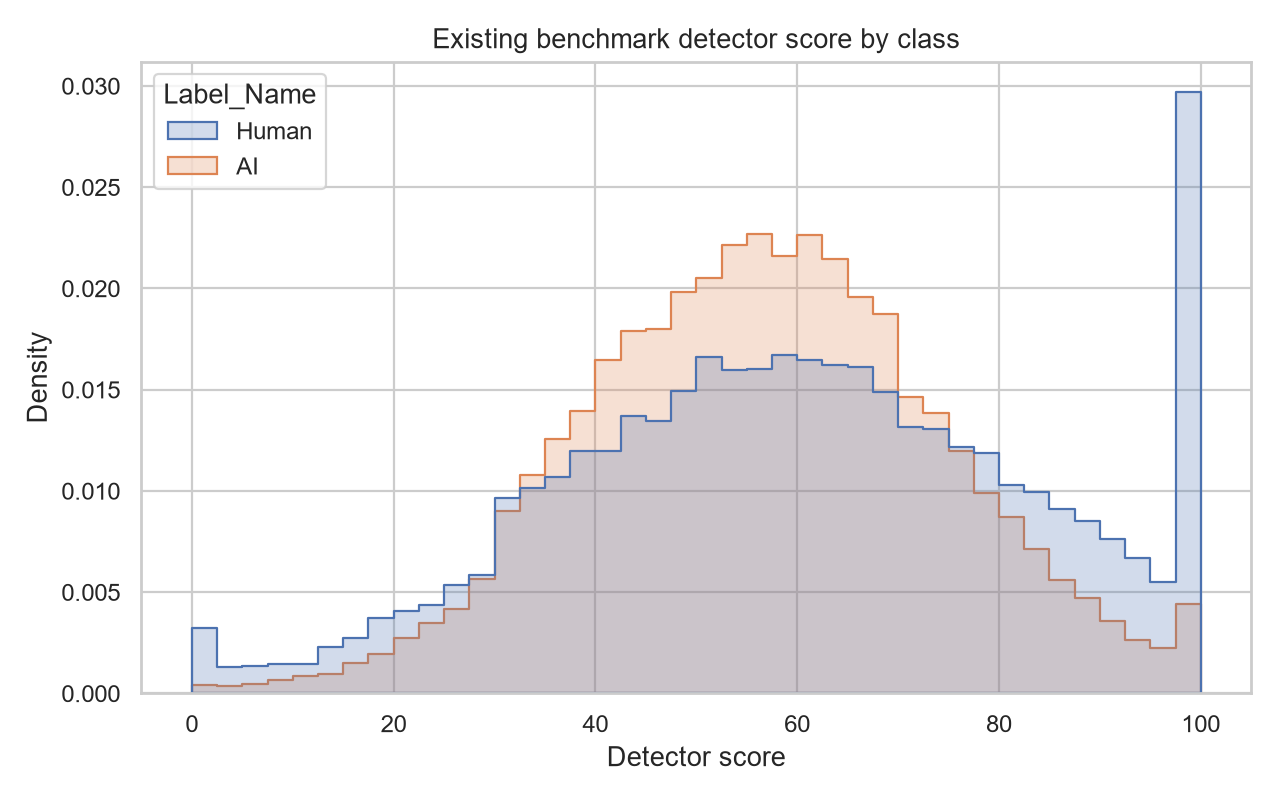

In [10]:
show("detector_score_by_class.png", 650)

## The precomputed `Formal_Tone_Score`

This score has an unexplained ceiling pattern that differs by class, and tone is easy
to change by prompting a model. It is excluded from the initial feature policy
(see `docs/formal_tone_score.md`).

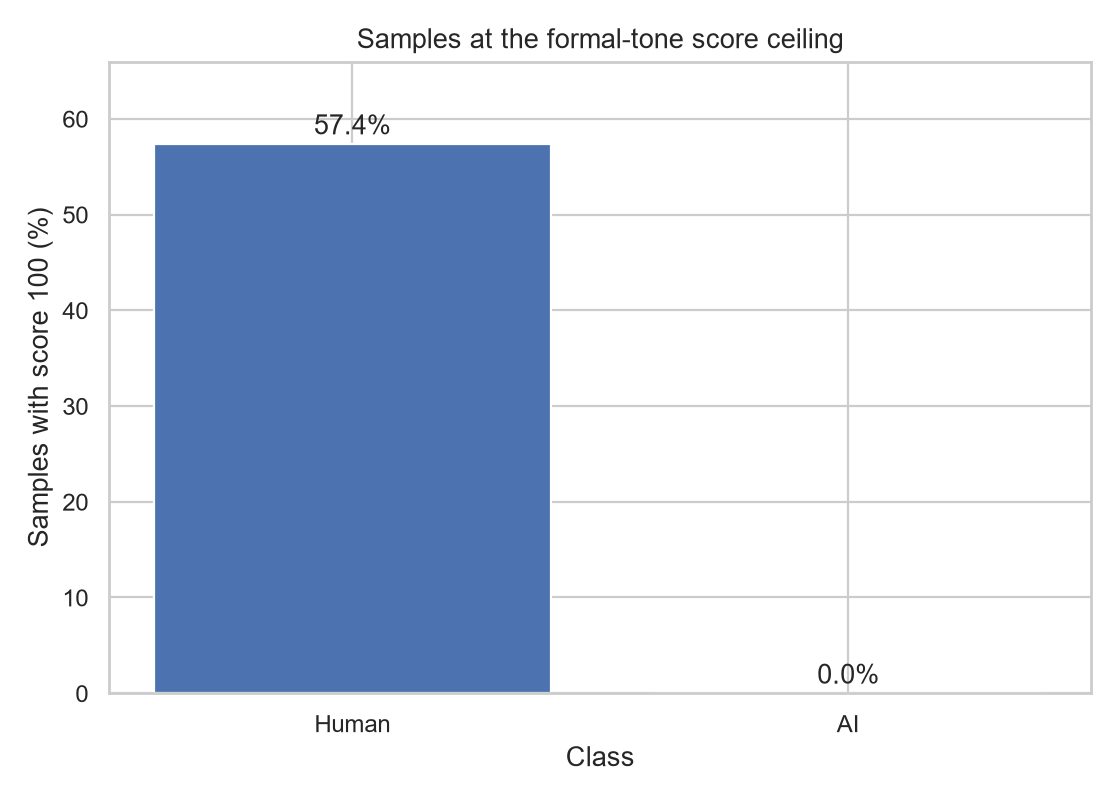

In [11]:
show("formal_tone_score_ceiling.png", 650)

## Text length by class

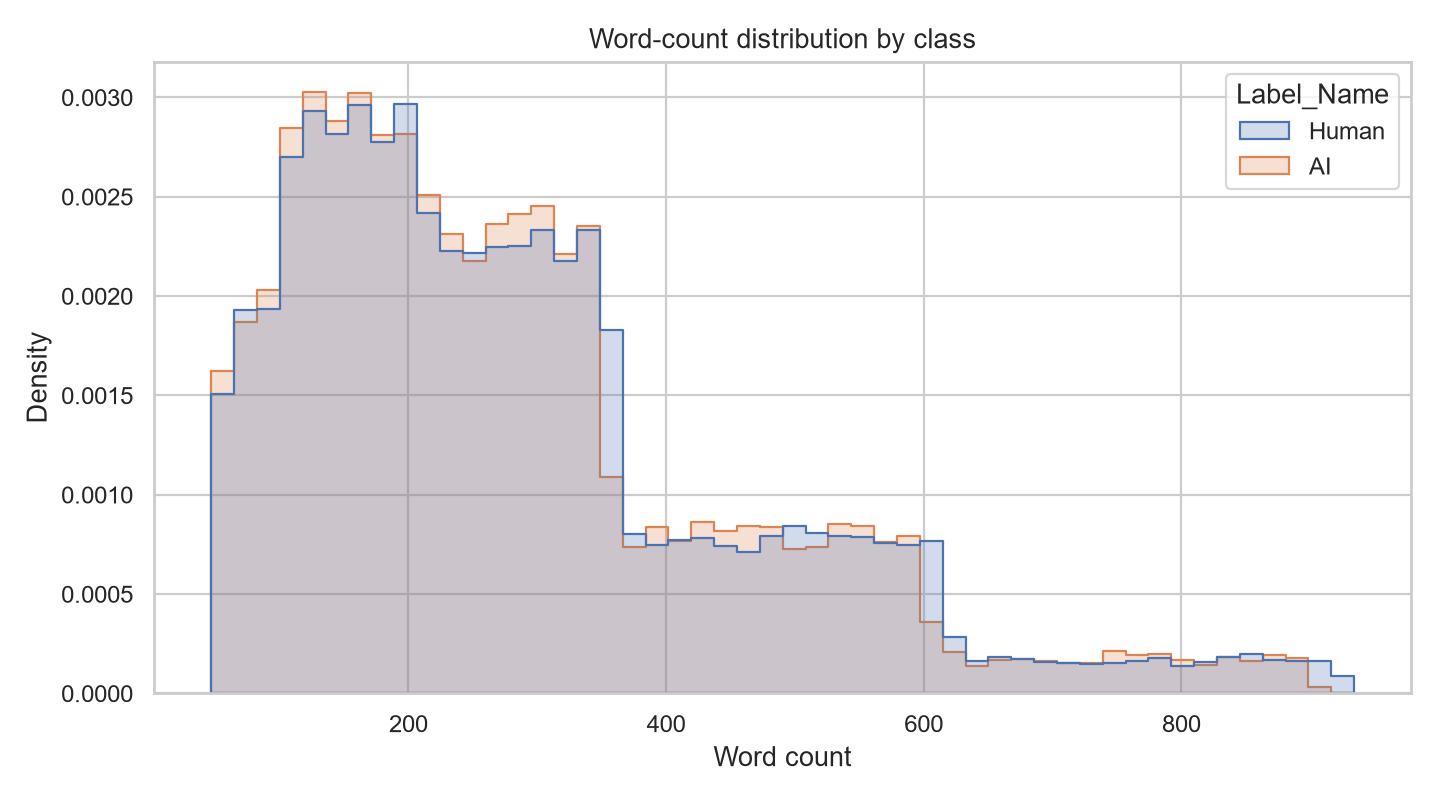

In [12]:
show("word_count_by_class.png", 650)

## Why machine learning

There is no simple written rule that separates human and AI text. We have 50,000
labeled examples, so a model can learn the boundary from data, and we can measure
how well it generalizes on held-out texts.

## Summary of limitations found so far
- The source does not document how its precomputed feature columns were calculated,
  so we **re-derive our own features from `Raw_Text`** (notebook 02).
- Metadata columns leak the label and are excluded.
- Notebook 02 shows that the texts come from only **11 writing templates**, which limits
  how far the results generalize.